# Predicting Automobile Fuel Efficiency

Academic machine-learning project by Colter Welden.

This project uses the UCI Auto MPG dataset to predict vehicle fuel
efficiency with a TensorFlow/Keras neural network. It compares
1,000 epochs of training with early stopping and evaluates the
models using MAE, MSE, and RMSE.

Dataset and reference:
- UCI Auto MPG: https://doi.org/10.24432/C5859H
- TensorFlow regression tutorial:
  https://www.tensorflow.org/tutorials/keras/regression

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

# Makes random model initialization more reproducible.
keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("pandas version:", pd.__version__)

TensorFlow version: 2.21.0
pandas version: 2.3.3


In [2]:
dataset_url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "auto-mpg/auto-mpg.data"
)

dataset_path = keras.utils.get_file(
    fname="auto-mpg.data",
    origin=dataset_url
)

print("Dataset saved at:")
print(dataset_path)

Dataset saved at:
C:\Users\Colte\.keras\datasets\auto-mpg.data


## Data loading and cleaning

In [3]:
column_names = [
    "MPG",
    "Cylinders",
    "Displacement",
    "Horsepower",
    "Weight",
    "Acceleration",
    "Model Year",
    "Origin"
]

raw_dataset = pd.read_csv(
    dataset_path,
    names=column_names,
    na_values="?",
    sep=r"\s+",
    usecols=range(8)
)

dataset = raw_dataset.copy()

print("Dataset shape:", dataset.shape)
dataset.tail()

Dataset shape: (398, 8)


,MPG,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
393,27.0,4,140.0,86.0,2790.0,15.6,82,1
394,44.0,4,97.0,52.0,2130.0,24.6,82,2
395,32.0,4,135.0,84.0,2295.0,11.6,82,1
396,28.0,4,120.0,79.0,2625.0,18.6,82,1
397,31.0,4,119.0,82.0,2720.0,19.4,82,1


In [4]:
dataset.isna().sum()

MPG             0
Cylinders       0
Displacement    0
Horsepower      6
Weight          0
Acceleration    0
Model Year      0
Origin          0
dtype: int64

In [5]:
# Remove the six rows with missing horsepower values.
dataset = dataset.dropna().copy()

print("Rows after cleaning:", len(dataset))
print("Missing values remaining:", dataset.isna().sum().sum())

# Randomly assign 80% of the records to training.
train_dataset = dataset.sample(frac=0.8, random_state=0)

# Use the remaining 20% for final testing.
test_dataset = dataset.drop(train_dataset.index)

print("Training rows:", len(train_dataset))
print("Testing rows:", len(test_dataset))

Rows after cleaning: 392
Missing values remaining: 0
Training rows: 314
Testing rows: 78


## Exploratory analysis

Examine the distributions and relationships among MPG, cylinder count,
engine displacement, and vehicle weight in the training data.

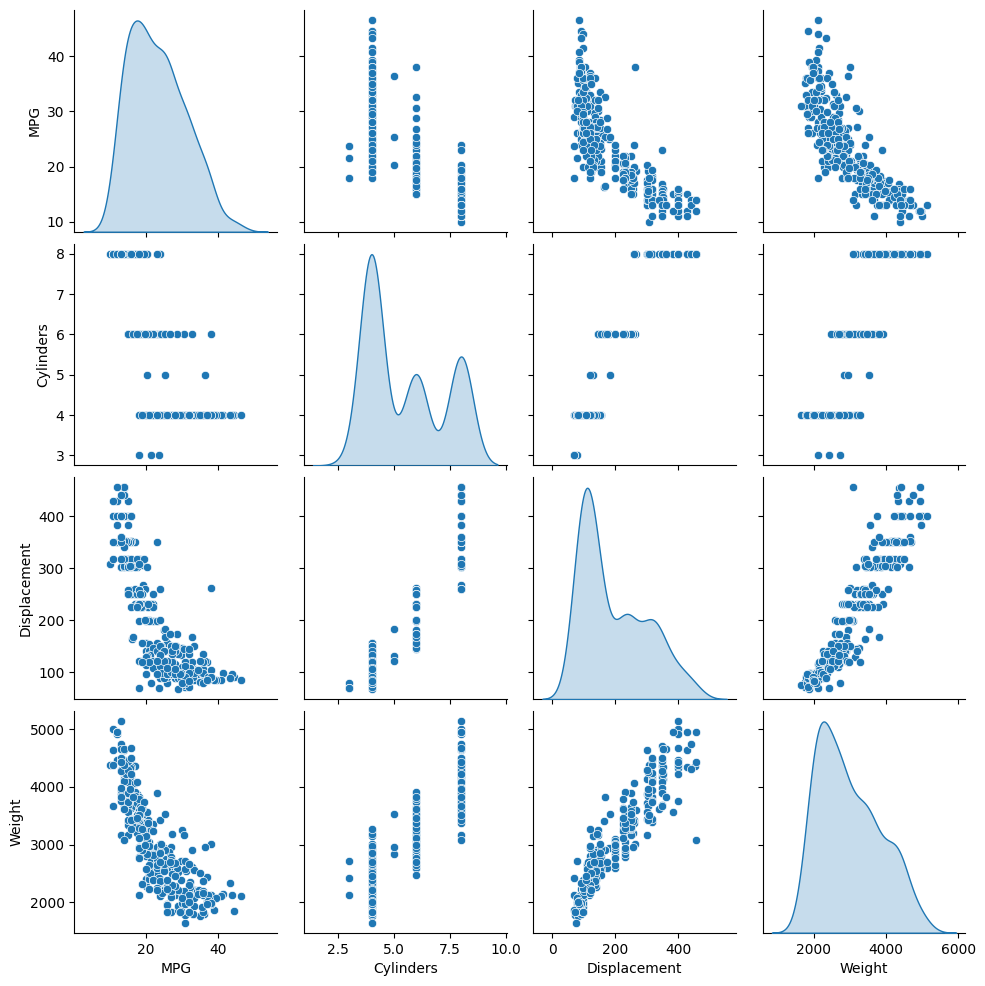

In [6]:
sns.pairplot(
    train_dataset[
        ["MPG", "Cylinders", "Displacement", "Weight"]
    ],
    diag_kind="kde"
)

plt.show()

## Preprocessing

Calculate feature means and standard deviations, separate MPG as the
prediction target, and standardize the inputs using training-set statistics.

In [7]:
train_stats = train_dataset.describe()

# MPG is the prediction target, so remove it from the feature statistics.
train_stats.pop("MPG")

# Transpose the table so each feature appears as a row.
train_stats = train_stats.transpose()

train_stats

,count,mean,std,min,25%,50%,75%,max
Cylinders,314.0,5.477707,1.699788,3.0,4.00,4.0,8.00,8.0
Displacement,314.0,195.318471,104.331589,68.0,105.50,151.0,265.75,455.0
Horsepower,314.0,104.869427,38.096214,46.0,76.25,94.5,128.00,225.0
Weight,314.0,2990.251592,843.898596,1649.0,2256.50,2822.5,3608.00,5140.0
Acceleration,314.0,15.559236,2.789230,8.0,13.80,15.5,17.20,24.8
Model Year,314.0,75.898089,3.675642,70.0,73.00,76.0,79.00,82.0
Origin,314.0,1.573248,0.800988,1.0,1.00,1.0,2.00,3.0


In [8]:
# Remove MPG from each dataset and store it separately as the target label.
train_labels = train_dataset.pop("MPG")
test_labels = test_dataset.pop("MPG")

print("Training feature shape:", train_dataset.shape)
print("Training label shape:", train_labels.shape)

print("Testing feature shape:", test_dataset.shape)
print("Testing label shape:", test_labels.shape)

train_dataset.head()

Training feature shape: (314, 7)
Training label shape: (314,)
Testing feature shape: (78, 7)
Testing label shape: (78,)


,Cylinders,Displacement,Horsepower,Weight,Acceleration,Model Year,Origin
146,4,90.0,75.0,2125.0,14.5,74,1
282,4,140.0,88.0,2890.0,17.3,79,1
69,8,350.0,160.0,4456.0,13.5,72,1
378,4,105.0,63.0,2125.0,14.7,82,1
331,4,97.0,67.0,2145.0,18.0,80,3


In [9]:
def norm(x):
    return (x - train_stats["mean"]) / train_stats["std"]

normed_train_data = norm(train_dataset)
normed_test_data = norm(test_dataset)

# Verify the training data.
normalization_check = (
    normed_train_data.describe()
    .transpose()[["mean", "std"]]
)

normalization_check

,mean,std
Cylinders,1.824443e-16,1.0
Displacement,8.627211e-17,1.0
Horsepower,-9.900078e-18,1.0
Weight,-8.485781e-17,1.0
Acceleration,-5.148041e-16,1.0
Model Year,9.772791e-16,1.0
Origin,-9.617219e-17,1.0


## Model architecture

Build a neural network with seven input features, two hidden layers
of 64 ReLU neurons each, and one output predicting MPG.


In [10]:
def build_model():
    model = keras.Sequential([
        keras.Input(shape=(len(train_dataset.columns),)),
        layers.Dense(64, activation="relu"),
        layers.Dense(64, activation="relu"),
        layers.Dense(1)
    ])

    optimizer = keras.optimizers.RMSprop(learning_rate=0.001)

    model.compile(
        loss="mse",
        optimizer=optimizer,
        metrics=["mae", "mse"]
    )

    return model


model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,737 (18.50 KB)

 Trainable params: 4,737 (18.50 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Select the first 10 training examples.
example_batch = normed_train_data.iloc[:10]

# Generate predictions before training.
example_result = model.predict(example_batch, verbose=0)

print("Predictions before training:")
print(example_result.flatten())

Predictions before training:
[ 0.13781431  0.13012657  0.10353583 -0.12650989 -0.1737465  -0.02781667
 -0.17841554 -0.1242024   0.03785629 -0.10565008]


In [12]:
prediction_check = pd.DataFrame({
    "Untrained Prediction": example_result.flatten(),
    "Actual MPG": train_labels.iloc[:10].values
})

prediction_check

,Untrained Prediction,Actual MPG
0,0.137814,28.0
1,0.130127,22.3
2,0.103536,12.0
3,-0.126510,38.0
4,-0.173746,33.8
5,-0.027817,19.4
6,-0.178416,38.1
7,-0.124202,30.0
8,0.037856,20.0
9,-0.105650,20.0


## Training and validation

Train the neural network for 1,000 epochs, reserving 20% of the
development data for validation. Compare training and validation
errors to assess learning progress and signs of overfitting.

In [13]:
EPOCHS = 1000

history = model.fit(
    normed_train_data,
    train_labels,
    epochs=EPOCHS,
    validation_split=0.2,
    verbose=0
)

print("Training complete.")

Training complete.


In [14]:
hist = pd.DataFrame(history.history)
hist["epoch"] = history.epoch

hist.tail()

,loss,mae,mse,val_loss,val_mae,val_mse,epoch
995,2.238488,0.858359,2.238488,9.471873,2.243035,9.471873,995
996,2.197693,0.832867,2.197693,9.519105,2.251768,9.519105,996
997,2.190495,0.834749,2.190495,9.493906,2.250319,9.493906,997
998,2.181947,0.827401,2.181947,9.492858,2.250010,9.492858,998
999,2.212835,0.843406,2.212835,9.515742,2.255809,9.515742,999


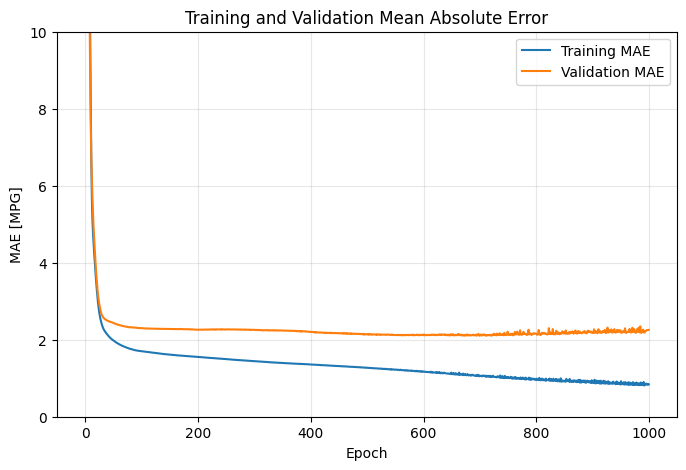

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(hist["epoch"], hist["mae"], label="Training MAE")
plt.plot(hist["epoch"], hist["val_mae"], label="Validation MAE")

plt.xlabel("Epoch")
plt.ylabel("MAE [MPG]")
plt.title("Training and Validation Mean Absolute Error")
plt.ylim([0, 10])
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

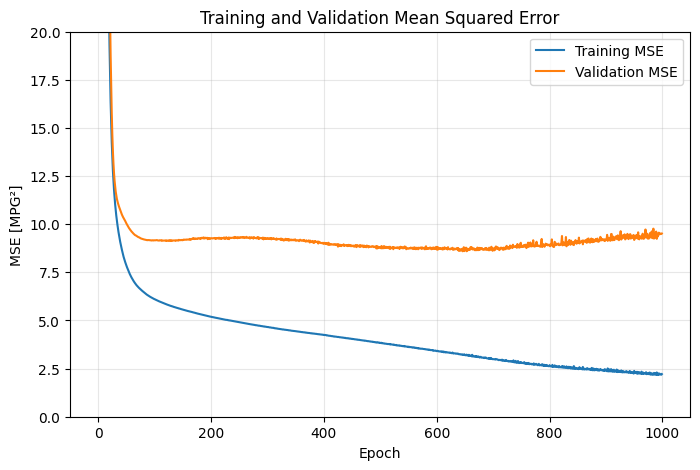

In [16]:
plt.figure(figsize=(8, 5))

plt.plot(hist["epoch"], hist["mse"], label="Training MSE")
plt.plot(hist["epoch"], hist["val_mse"], label="Validation MSE")

plt.xlabel("Epoch")
plt.ylabel("MSE [MPG²]")
plt.title("Training and Validation Mean Squared Error")
plt.ylim([0, 20])
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [17]:
best_mae_epoch = hist["val_mae"].idxmin()
best_mse_epoch = hist["val_mse"].idxmin()

print("Lowest validation MAE:")
print(f"Epoch: {best_mae_epoch}")
print(f"Validation MAE: {hist.loc[best_mae_epoch, 'val_mae']:.4f} MPG")

print("\nLowest validation MSE:")
print(f"Epoch: {best_mse_epoch}")
print(f"Validation MSE: {hist.loc[best_mse_epoch, 'val_mse']:.4f} MPG²")

Lowest validation MAE:
Epoch: 699
Validation MAE: 2.1036 MPG

Lowest validation MSE:
Epoch: 646
Validation MSE: 8.5948 MPG²


## Test evaluation

Evaluate the 1,000-epoch model on the held-out test set.
Report mean absolute error (MAE), mean squared error (MSE),
and root mean squared error (RMSE).

In [18]:
test_loss, test_mae, test_mse = model.evaluate(
    normed_test_data,
    test_labels,
    verbose=0
)

print("1,000-Epoch Model Test Results")
print(f"MAE: {test_mae:.4f} MPG")
print(f"MSE: {test_mse:.4f} MPG²")
print(f"RMSE: {np.sqrt(test_mse):.4f} MPG")

1,000-Epoch Model Test Results
MAE: 2.0109 MPG
MSE: 6.1016 MPG²
RMSE: 2.4701 MPG


## Early stopping experiment

In [19]:
# Reset the seed before constructing a fresh model.
keras.utils.set_random_seed(42)

early_stop_model = build_model()

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=50,
    restore_best_weights=True
)

early_history = early_stop_model.fit(
    normed_train_data,
    train_labels,
    epochs=1000,
    validation_split=0.2,
    verbose=0,
    callbacks=[early_stop]
)

print("Training stopped after", len(early_history.history["loss"]), "epochs")
print(
    "Best validation MSE:",
    f"{min(early_history.history['val_loss']):.4f} MPG²"
)

Training stopped after 171 epochs
Best validation MSE: 9.1310 MPG²


In [20]:
early_test_loss, early_test_mae, early_test_mse = early_stop_model.evaluate(
    normed_test_data,
    test_labels,
    verbose=0
)

print("Early-Stopping Model Test Results")
print(f"MAE: {early_test_mae:.4f} MPG")
print(f"MSE: {early_test_mse:.4f} MPG²")
print(f"RMSE: {np.sqrt(early_test_mse):.4f} MPG")

Early-Stopping Model Test Results
MAE: 1.9439 MPG
MSE: 6.4123 MPG²
RMSE: 2.5322 MPG


## Model comparison

In [21]:
model_comparison = pd.DataFrame({
    "Model": [
        "1,000-Epoch Model",
        "Early-Stopping Model"
    ],
    "Test MAE (MPG)": [
        test_mae,
        early_test_mae
    ],
    "Test MSE (MPG²)": [
        test_mse,
        early_test_mse
    ],
    "Test RMSE (MPG)": [
        np.sqrt(test_mse),
        np.sqrt(early_test_mse)
    ]
})

model_comparison.round(4)

,Model,Test MAE (MPG),Test MSE (MPG²),Test RMSE (MPG)
0,"1,000-Epoch Model",2.0109,6.1016,2.4701
1,Early-Stopping Model,1.9439,6.4123,2.5322


## Interpretation and limitations

The early-stopping model recorded a test MAE of 1.9439 MPG,
compared with 2.0109 MPG for the 1,000-epoch model. However,
the 1,000-epoch model recorded a lower RMSE: 2.4701 MPG
compared with 2.5322 MPG.

Early stopping used fewer training epochs, but neither model
performed better across both metrics. These results describe
one dataset split and do not establish consistent superiority.

Normalization statistics were calculated before separating the
validation subset. The test data remained excluded from those
calculations. Future work should split training and validation
data before fitting preprocessing.

Other improvements include categorical encoding of Origin,
comparison with simple regression baselines, residual analysis,
and evaluation across multiple random seeds.